# Plotting Batch-Generated Random Functions

This notebook demonstrates how to use the `FastWaveletBatchGenerator` from `random_besov.py` to efficiently generate and plot multiple random functions.

The process is as follows:
1. **Initialize `FastWaveletBatchGenerator`**: This class handles the interaction with the underlying CUDA code. The first time it is initialized, it will automatically compile the `wavelet_fast.cu` kernel, which may take a few moments.
2. **Define Parameters**: We create a list of parameter dictionaries. Each dictionary specifies the properties (`d`, `alpha`, `J`, `seed`) for one random function in the batch.
3. **Define Input Grids**: We create a corresponding list of input NumPy arrays (`X_list`). This example showcases the ability to use a different number of evaluation points (`N`) for each function.
4. **Generate Batch**: We call `generate_batch()` once to create all the functions in a single, highly parallelized GPU operation.
5. **Plot Results**: We use `matplotlib` to visualize the generated functions.

When using Windows, open "x64 Native Tools Command Prompt for VS 2019", then cd and run "nvcc -O3 wavelet_fast.cu -o wavelet_fast.dll -lcurand -shared".

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import torch

# Add the current directory to the path to ensure the notebook can find the local module
if os.path.abspath('.') not in sys.path:
    sys.path.append(os.path.abspath('.'))

from random_besov import FastWaveletBatchGenerator

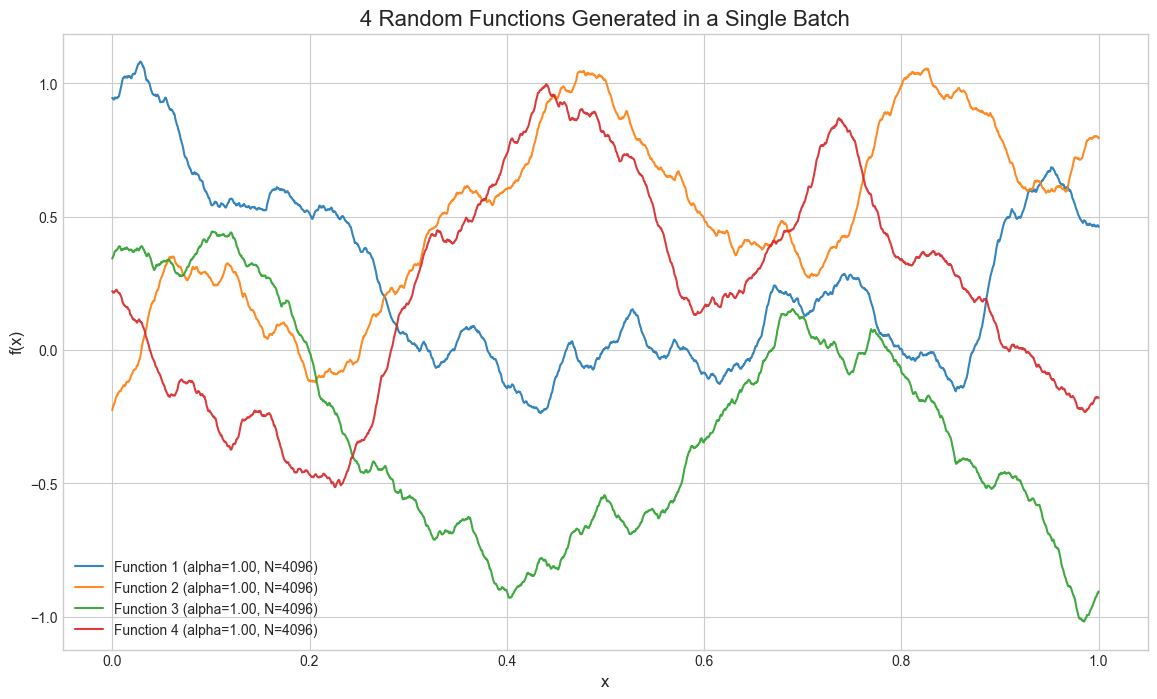

In [27]:
# Define parameters for a batch of 4 functions
params = {'d': 1, 'alpha': 1, 'J': 12, 'C0': 1.0}
X_list = []
num_functions = 4
for i in range(num_functions):
    X_list.append(np.linspace(0, 1, 4096).reshape(-1, 1)) 



# Generate all functions in a single batch call
random_besov_generator = FastWaveletBatchGenerator(wavelet='db6', cascade_level=8)
Y_list = random_besov_generator.generate_batch(X_list, params)
random_besov_generator.cleanup()


# Plot the results
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(14, 8))

for i in range(num_functions):
    x_coords = X_list[i].flatten()
    y_coords = Y_list[i]
    alpha_val = params['alpha']
    ax.plot(x_coords, y_coords, label=f'Function {i+1} (alpha={alpha_val:.2f}, N={len(x_coords)})', alpha=0.9)

ax.set_title(f'{num_functions} Random Functions Generated in a Single Batch', fontsize=16)
ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('f(x)', fontsize=12)
ax.legend()
ax.grid(True)
plt.show()

In [24]:
def sample_unit_ball(n, d):
    z = np.random.normal(size=(n, d))
    z /= np.linalg.norm(z, axis=1, keepdims=True)
    r = np.random.uniform(size=(n, 1)) ** (1 / d)
    return r * z

def sample_stiefel(d, p):
    if p > d:
        raise ValueError("p must be <= d")

    Z = np.random.normal(size=(d, p))
    Q, R = np.linalg.qr(Z)

    signs = np.sign(np.diag(R))
    signs[signs == 0] = 1
    Q *= signs

    return Q

def random_project(X, p):
    d = X.shape[1]
    U = sample_stiefel(d, p)
    X_projected = (np.matmul(X, U) + 1) / 2
    return X_projected

###### Generate pretraining data for in-context regression transformer model

def generate_pretrain_data(batch_size, n, d, p, alpha, J, cascade_level, d_embd, sigma, C0=1.0):
    """
    Generates function data and prepares it for an in-context regression transformer model.

    Args:
        batch_size (int): number of functions in the batch.
        n (int): number of data points per function.
        d (int): input dimension.
        p (int): projection dimension.
        alpha (float): smoothness parameter.
        J (int): maximum wavelet scale.
        cascade_level (int): cascade level for wavelet generation.
        d_embd (int): The embedding dimension for the transformer input.
        sigma (float): The standard deviation of Gaussian noise to add to the Y values.
        C0 (float): scaling constant for the wavelet function.

    Returns:
        tuple[torch.Tensor, torch.Tensor]:
        - A tensor of shape (batch_size, N, d_embd) containing the
          concatenated and padded X and Y sequences. The last Y value
          in each sequence is masked with 0.
        - A tensor of shape (batch_size,) containing the true last Y value
          for each sequence, which serves as the regression target.
    """
    X_list = []
    X_projected_list = []
    for _ in range(batch_size):
        X = sample_unit_ball(n, d)
        X_list.append(X)
        X_projected_list.append(random_project(X, p))


    params = {'d': p, 'alpha': alpha, 'J': J, 'C0': C0}
    generator = FastWaveletBatchGenerator(wavelet='db6', cascade_level=cascade_level)
    Y_list = generator.generate_batch(X_projected_list, params)
    generator.cleanup()

    device = torch.device('cuda')

    if (d + 3) > d_embd:
        raise ValueError(f"d_embd ({d_embd}) must be greater than or equal to the input dimension + 3 ({d + 3}).")

    batch_size = len(X_list)

    # Initialize output tensors
    output_sequences = torch.zeros((batch_size, n, d_embd), dtype=torch.float32, device=device)
    target_values = torch.zeros(batch_size, dtype=torch.float32, device=device)

    for i in range(batch_size):
        # Get original data
        X_i = X_list[i]
        Y_i = Y_list[i]
        
        # Add noise
        Y_i += np.random.normal(scale=sigma, size=Y_i.shape)

        # Get the target value (the last Y value)
        target_values[i] = torch.as_tensor(Y_i[-1], device=device)
        
        # Prepare the input sequence
        # Convert X to a tensor
        X_i_torch = torch.from_numpy(np.asarray(X_i, dtype=np.float32)).to(device)
        if X_i_torch.ndim == 1:
            X_i_torch = X_i_torch.unsqueeze(-1)
        
        # Mask the last Y value
        Y_i[-1] = 0
        Y_i_torch = torch.from_numpy(np.asarray(Y_i, dtype=np.float32)).to(device)

        # Concatenate X and Y_masked
        # Y_masked needs to be shaped as (n, 1)
        xy_concat = torch.cat((X_i_torch, Y_i_torch.unsqueeze(-1)), dim=1)
        
        # Place the concatenated sequence into the padded output tensor
        output_sequences[i, :n, :(d + 1)] = xy_concat
        output_sequences[i, n - 1, d + 1] = 1

    return output_sequences, target_values

In [28]:
import time

start = time.time()
prompts, target_values = generate_pretrain_data(batch_size=1000, n=100, d=10, p=1, alpha=2, J=10, cascade_level=8, d_embd=1024, sigma=0.01, C0=1.0)
end = time.time()

print("Elapsed:", end - start, "seconds")

Elapsed: 1.00661301612854 seconds


In [31]:
start = time.time()
prompts, target_values = generate_pretrain_data(batch_size=1000, n=100, d=10, p=2, alpha=3, J=6, cascade_level=6, d_embd=1024, sigma=0.01, C0=1.0)
end = time.time()

print("Elapsed:", end - start, "seconds")

Elapsed: 1.6076159477233887 seconds
